In [1]:
import sys
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from statsbombpy import sb

sys.path.append("..")

from src.load import loadMatches, loadEvents, RAW

# Tactics: risk map, team styles and influential players
Everything here is built on the model outputs: the pass model's xPass and the danger value of each action.

## Loading the pass predictions

In [2]:
xpass = pd.read_parquet("../outputs/xpass_oof.parquet")
passes = pd.read_parquet("../data/clean/passes.parquet", columns=["id", "pass_length", "pass_angle", "pass_cross", "pass_switch", "pass_through_ball", "pass_height"])
xpass = xpass.merge(passes, on="id", how="left")

matches = loadMatches()
xpass = xpass.merge(matches[["match_id", "competition", "season"]], on="match_id", how="left")
xpass["league"] = xpass["competition"] + " " + xpass["season"]

print("Passes:", len(xpass))
print("Missing xPass:", xpass["xpass"].isna().sum())

Passes: 371845
Missing xPass: 0


## Risk map
For each team in each competition:
- risk = 1 − average xPass. A team that tries hard passes has a low average xPass, so a high risk.
- execution = completion rate − average xPass. Above 0 means the team completes more passes than the model expects for passes that hard.

In [3]:
MIN_PASSES = 1000


def riskTable(xpass):
    """Risk and execution for every team in every competition."""
    grouped = xpass.groupby(["league", "team"])
    table = pd.DataFrame()
    table["passes"] = grouped.size()
    table["matches"] = grouped["match_id"].nunique()
    table["completion"] = grouped["success"].mean()
    table["expected"] = grouped["xpass"].mean()
    table["risk"] = 1 - table["expected"]
    table["execution"] = table["completion"] - table["expected"]
    table = table[table["passes"] >= MIN_PASSES]
    return table.reset_index()


risk = riskTable(xpass)

print("Teams on the map:", len(risk))
print(risk.sort_values("execution", ascending=False).head(10).round(3).to_string(index=False))

Teams on the map: 129
                                             league          team  passes  matches  completion  expected  risk  execution
                            Europe - UEFA Euro 2024       Germany    3064        5       0.889     0.871 0.129      0.018
                            Europe - UEFA Euro 2020       Denmark    2647        6       0.830     0.813 0.187      0.016
                    Europe - UEFA Women's Euro 2025 Spain Women's    3977        6       0.869     0.854 0.146      0.015
                            Europe - UEFA Euro 2020       Germany    2274        4       0.881     0.867 0.133      0.014
United States of America - Major League Soccer 2023   Inter Miami    1497        3       0.857     0.845 0.155      0.012
                            Europe - UEFA Euro 2024         Spain    3738        7       0.884     0.872 0.128      0.012
                          Spain - La Liga 2020/2021     Barcelona   24207       35       0.893     0.881 0.119      0.011
  

In [4]:
print("Lowest execution:")
print(risk.sort_values("execution").head(5).round(3).to_string(index=False))

Lowest execution:
                                league                 team  passes  matches  completion  expected  risk  execution
International - Women's World Cup 2023 South Africa Women's    1046        4       0.603     0.672 0.328     -0.069
International - Women's World Cup 2023      Morocco Women's    1025        4       0.612     0.672 0.328     -0.061
       Europe - UEFA Women's Euro 2022      Austria Women's    1386        4       0.689     0.741 0.259     -0.052
International - Women's World Cup 2023      Nigeria Women's    1207        4       0.692     0.731 0.269     -0.039
International - Women's World Cup 2023      Jamaica Women's    1089        4       0.626     0.664 0.336     -0.037


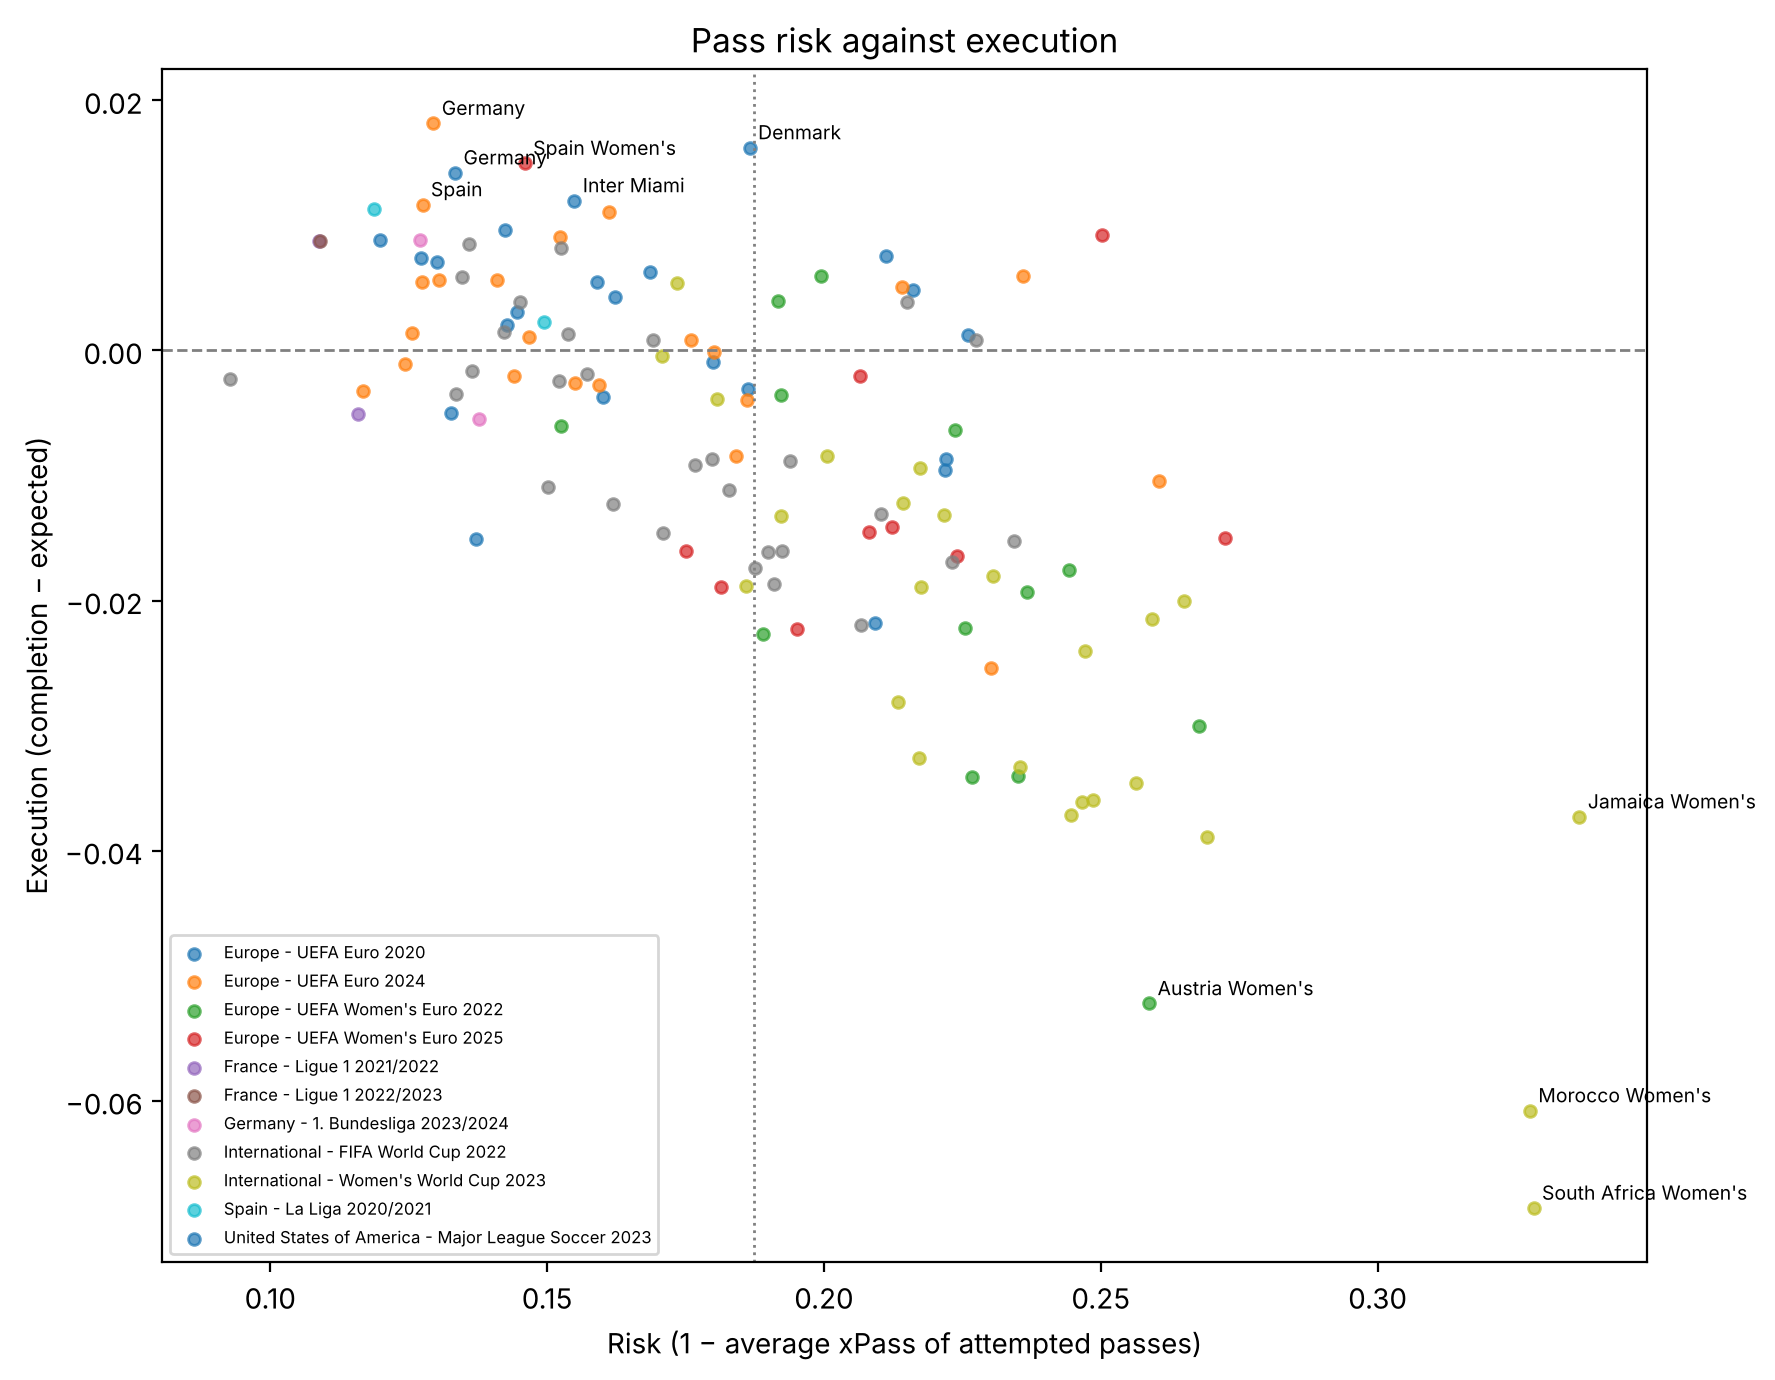

In [5]:
LABELS = 6


def plotRisk(risk, ax):
    """Scatter of risk against execution with the extreme teams named."""
    for league, group in risk.groupby("league"):
        ax.scatter(group["risk"], group["execution"], s=18, alpha=0.7, label=league)
    named = pd.concat([risk.nlargest(LABELS, "execution"), risk.nsmallest(LABELS // 2, "execution"), risk.nlargest(LABELS // 2, "risk")])
    for index, row in named.drop_duplicates().iterrows():
        ax.annotate(row["team"], (row["risk"], row["execution"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.axvline(risk["risk"].mean(), color="grey", linestyle=":", linewidth=1)
    ax.set_xlabel("Risk (1 − average xPass of attempted passes)")
    ax.set_ylabel("Execution (completion − expected)")
    ax.set_title("Pass risk against execution")


fig, ax = plt.subplots(figsize=(9, 7))
plotRisk(risk, ax)
ax.legend(fontsize=6, loc="lower left")
plt.tight_layout()
plt.savefig("../outputs/fig2_risk_map.png", dpi=150)
plt.show()

Execution is measured on out-of-fold predictions for training matches, so a team's own passes never trained the model that scores them.

## Team styles with k-means
Each team in each competition becomes 8 passing numbers. k-means puts teams with similar numbers into the same group.

In [6]:
LONG = 30
FINAL_THIRD = 80


def styleTable(xpass):
    """The 8 passing features for every team in every competition."""
    xpass = xpass.copy()
    xpass["forwardPass"] = (np.cos(xpass["pass_angle"]) > 0.5).astype(int)
    xpass["longPass"] = (xpass["pass_length"] >= LONG).astype(int)
    xpass["finalThird"] = (xpass["x"] >= FINAL_THIRD).astype(int)
    xpass["highPass"] = (xpass["pass_height"] == "High Pass").astype(int)

    grouped = xpass.groupby(["league", "team"])
    table = pd.DataFrame()
    table["passesPerMatch"] = grouped.size() / grouped["match_id"].nunique()
    table["forwardShare"] = grouped["forwardPass"].mean()
    table["averageLength"] = grouped["pass_length"].mean()
    table["longShare"] = grouped["longPass"].mean()
    table["highShare"] = grouped["highPass"].mean()
    table["finalThirdShare"] = grouped["finalThird"].mean()
    table["crossShare"] = grouped["pass_cross"].mean()
    table["risk"] = 1 - grouped["xpass"].mean()
    table["passes"] = grouped.size()
    table = table[table["passes"] >= MIN_PASSES]
    return table.drop(columns=["passes"])


styles = styleTable(xpass)
FEATURES = styles.columns.tolist()

print("Teams:", len(styles))
print(styles.describe().round(3))

Teams: 129
       passesPerMatch  forwardShare  averageLength  longShare  highShare  \
count         129.000       129.000        129.000    129.000    129.000   
mean          445.430         0.427         20.110      0.173      0.181   
std           103.310         0.052          1.268      0.032      0.055   
min           256.250         0.316         16.962      0.098      0.073   
25%           365.333         0.386         19.277      0.154      0.134   
50%           436.000         0.420         20.159      0.170      0.181   
75%           505.800         0.456         20.931      0.195      0.219   
max           871.750         0.621         23.335      0.288      0.342   

       finalThirdShare  crossShare     risk  
count          129.000     129.000  129.000  
mean             0.226       0.023    0.187  
std              0.044       0.006    0.048  
min              0.121       0.011    0.093  
25%              0.196       0.018    0.147  
50%              0.226      

The features are on very different scales (passes per match is in the hundreds, shares are below 1), so they are standardised first. Otherwise passes per match would decide the groups on its own.

In [7]:
mean = styles.mean()
spread = styles.std()
scaled = (styles - mean) / spread

## Choosing the number of groups
We try 2 to 8 groups and look at two things: the inertia (how tight the groups are) and the silhouette score (how well separated they are, higher is better).

   k  inertia  silhouette
0  2  596.914       0.345
1  3  498.893       0.235
2  4  426.277       0.250
3  5  371.670       0.233
4  6  325.479       0.247
5  7  294.970       0.249
6  8  272.129       0.249


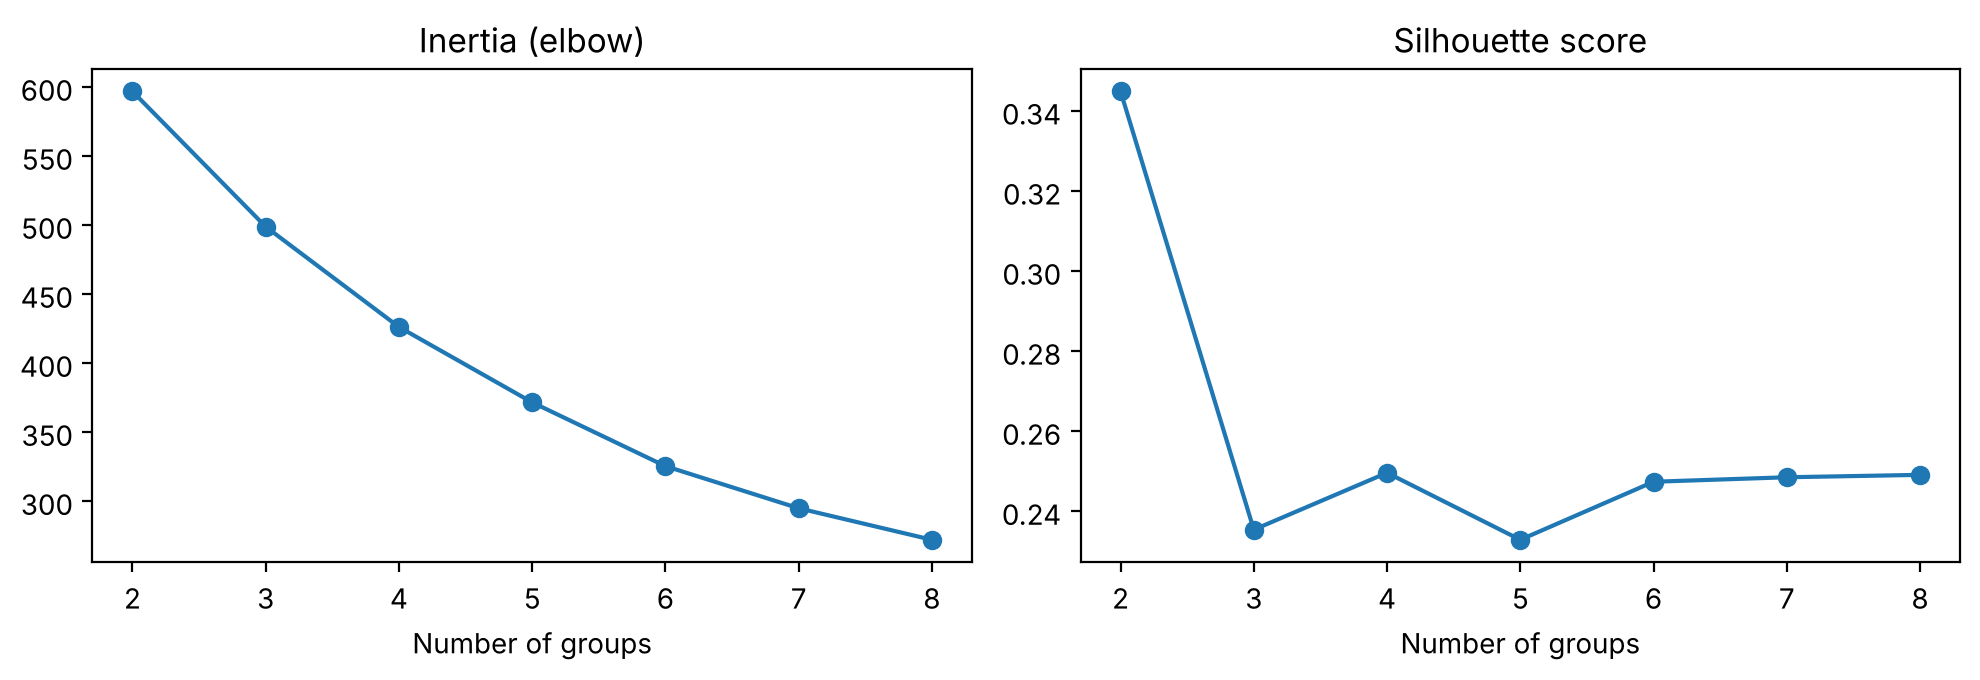

In [8]:
SEED = 2026

tries = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(scaled)
    tries.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette_score(scaled, labels)})

tries = pd.DataFrame(tries)
print(tries.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(tries["k"], tries["inertia"], marker="o")
axes[0].set_title("Inertia (elbow)")
axes[1].plot(tries["k"], tries["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
for ax in axes:
    ax.set_xlabel("Number of groups")
plt.tight_layout()
plt.show()

In [9]:
K = int(tries.sort_values("silhouette", ascending=False).iloc[0]["k"])
K = max(K, 3)

model = KMeans(n_clusters=K, n_init=20, random_state=SEED)
styles["group"] = model.fit_predict(scaled)

print("Groups used:", K)
print(styles["group"].value_counts().sort_index())

Groups used: 3
group
0    39
1    46
2    44
Name: count, dtype: int64


We take the k with the best silhouette, but never fewer than 3 groups, because 2 groups would only split "a lot of possession" from "not much" and say little about style.

## What each group looks like
The centres are shown in standard deviations from the average team, so +1 means one standard deviation more than a normal team.

In [10]:
centres = pd.DataFrame(model.cluster_centers_, columns=FEATURES).round(2)
print(centres.to_string())

   passesPerMatch  forwardShare  averageLength  longShare  highShare  finalThirdShare  crossShare  risk
0           -0.81          0.92           0.79       0.94       1.12            -0.02        0.87  1.08
1            0.95         -0.87          -0.82      -0.90      -0.98             0.64       -0.33 -0.93
2           -0.27          0.09           0.17       0.11       0.04            -0.65       -0.43  0.02


In [11]:
def describeGroup(centre):
    """Name a group by its two strongest features."""
    strongest = centre.abs().sort_values(ascending=False).index[:2]
    words = []
    for feature in strongest:
        if centre[feature] > 0:
            words.append("more " + feature)
        else:
            words.append("less " + feature)
    return ", ".join(words)


for group in range(K):
    members = styles[styles["group"] == group].reset_index()
    print("Group", group, "-", describeGroup(centres.loc[group]))
    print("   ", ", ".join(members["team"].head(8).tolist()))

Group 0 - more highShare, more risk
    Czech Republic, Poland, Russia, Scotland, Wales, Hungary, Romania, Slovenia
Group 1 - less highShare, more passesPerMatch
    Belgium, France, Germany, Italy, Netherlands, Portugal, Spain, Ukraine
Group 2 - less finalThirdShare, less crossShare
    Austria, Croatia, Denmark, England, North Macedonia, Slovakia, Sweden, Switzerland


In [12]:
styles.reset_index().to_csv("../outputs/team_styles.csv", index=False)

## Style groups on a picture
Passes per match against forward share, coloured by group.

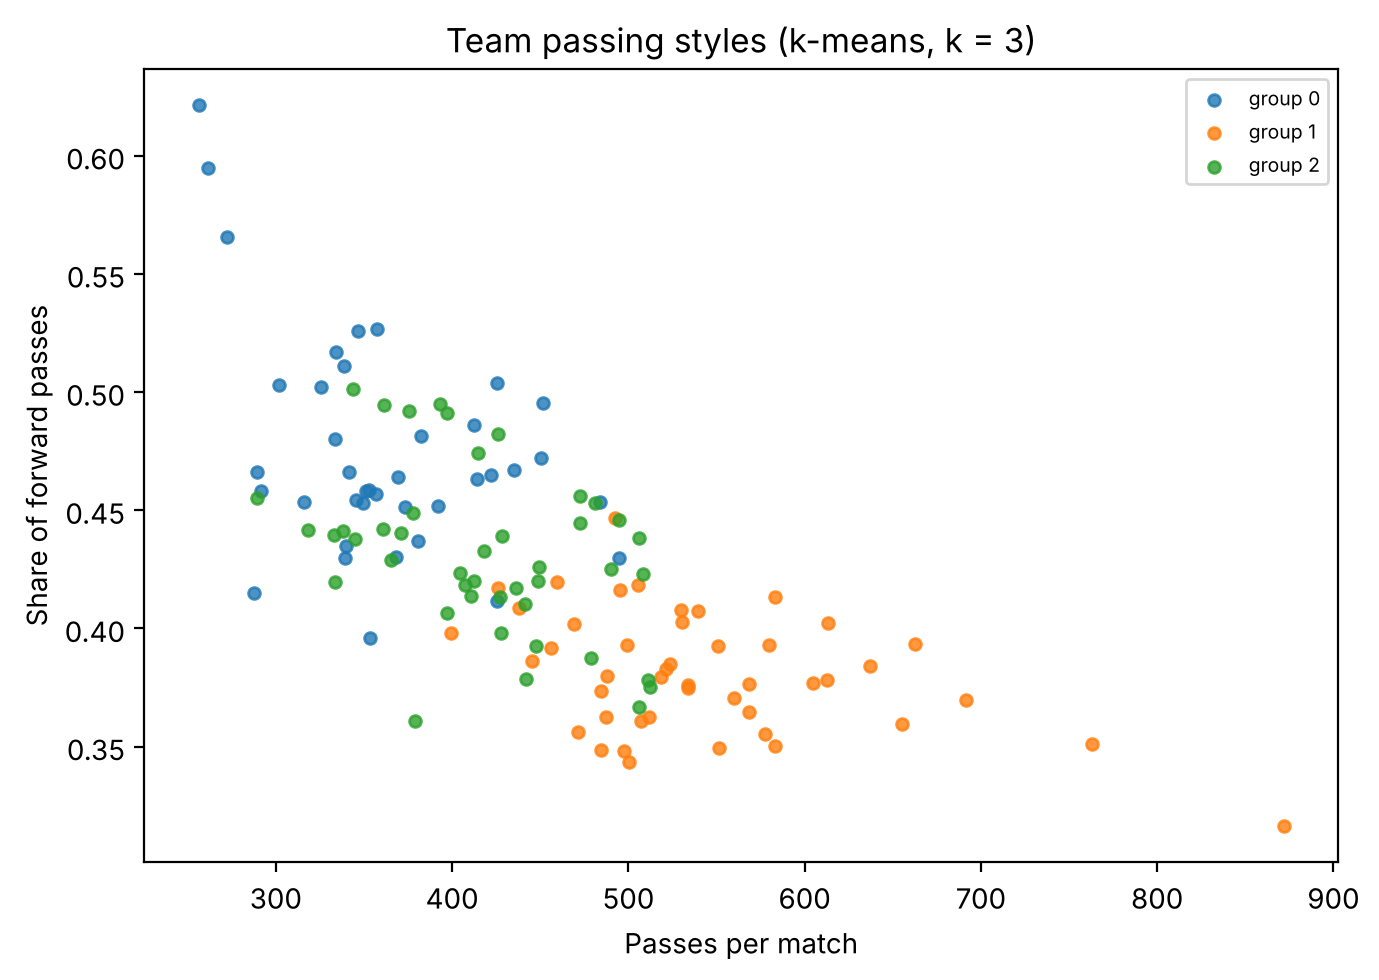

In [13]:
def plotStyles(styles, ax):
    """Scatter of two style features coloured by group."""
    for group in sorted(styles["group"].unique()):
        members = styles[styles["group"] == group]
        ax.scatter(members["passesPerMatch"], members["forwardShare"], s=18, alpha=0.8, label="group " + str(group))
    ax.set_xlabel("Passes per match")
    ax.set_ylabel("Share of forward passes")
    ax.set_title("Team passing styles (k-means, k = " + str(K) + ")")
    ax.legend(fontsize=7)


fig, ax = plt.subplots(figsize=(7, 5))
plotStyles(styles, ax)
plt.tight_layout()
plt.savefig("../outputs/fig2_styles.png", dpi=150)
plt.show()

## Influential players: danger created per 90 minutes
Each pass, carry and dribble gets a danger value: how much it changed the chance that the team scores within its next 10 actions. We add these up for every player and divide by minutes played.

The danger values should come from Anish's action_values.parquet (due Nov 25). Until then we use a simple stand-in, the fallback written in our plan: the chance of scoring within 10 actions from each zone of the pitch, counted from the training matches. When his file exists, set VALUES_COLUMN to its column and this notebook uses it instead.

In [14]:
VALUES_FILE = Path("../outputs/action_values.parquet")
VALUES_COLUMN = "value"
ACTIONS = ["Pass", "Carry", "Dribble", "Shot"]
WINDOW = 10

In [15]:
def matchActions(events):
    """Passes, carries, dribbles and shots of one match in order, with the 10-action label."""
    actions = events[events["type"].isin(ACTIONS)].copy()
    actions = actions[actions["period"] != 5]
    actions = actions.sort_values("index").reset_index(drop=True)

    goal = ((actions["type"] == "Shot") & (actions.get("shot_outcome") == "Goal")).to_numpy()
    teams = actions["team"].to_numpy()
    periods = actions["period"].to_numpy()

    labels = np.zeros(len(actions), dtype=int)
    for i in range(len(actions)):
        for j in range(i, min(i + WINDOW, len(actions))):
            if periods[j] != periods[i]:
                break
            if goal[j] and teams[j] == teams[i]:
                labels[i] = 1
                break
    actions["scores"] = labels

    actions["x"] = actions["location"].apply(lambda spot: spot[0])
    actions["y"] = actions["location"].apply(lambda spot: spot[1])
    actions["endX"] = np.nan
    actions["endY"] = np.nan
    for kind, column in [("Pass", "pass_end_location"), ("Carry", "carry_end_location")]:
        rows = actions["type"] == kind
        actions.loc[rows, "endX"] = actions.loc[rows, column].apply(lambda spot: spot[0])
        actions.loc[rows, "endY"] = actions.loc[rows, column].apply(lambda spot: spot[1])

    actions["completed"] = 1
    if "pass_outcome" in actions.columns:
        actions.loc[(actions["type"] == "Pass") & actions["pass_outcome"].notna(), "completed"] = 0
    if "dribble_outcome" in actions.columns:
        actions.loc[(actions["type"] == "Dribble") & (actions["dribble_outcome"] != "Complete"), "completed"] = 0
    return actions[["id", "match_id", "team", "player_id", "player", "type", "x", "y", "endX", "endY", "completed", "scores"]]

In [16]:
matches360 = matches[matches["has360"] == True]
allActions = []
for matchId in matches360["match_id"]:
    allActions.append(matchActions(loadEvents(matchId)))

actions = pd.concat(allActions, ignore_index=True)

print("Actions:", len(actions))
print(actions["type"].value_counts())
print("Share followed by a goal within 10 actions:", round(actions["scores"].mean(), 4))

Actions: 832998
type
Pass       447978
Carry      360885
Dribble     13271
Shot        10864
Name: count, dtype: int64
Share followed by a goal within 10 actions: 0.0125


## Stand-in danger: a zone table
The pitch is cut into 12 × 8 zones of 10 × 10 yards. A zone's danger is the share of actions starting there that are followed by a goal within 10 actions. Only training matches are used to fill the table.

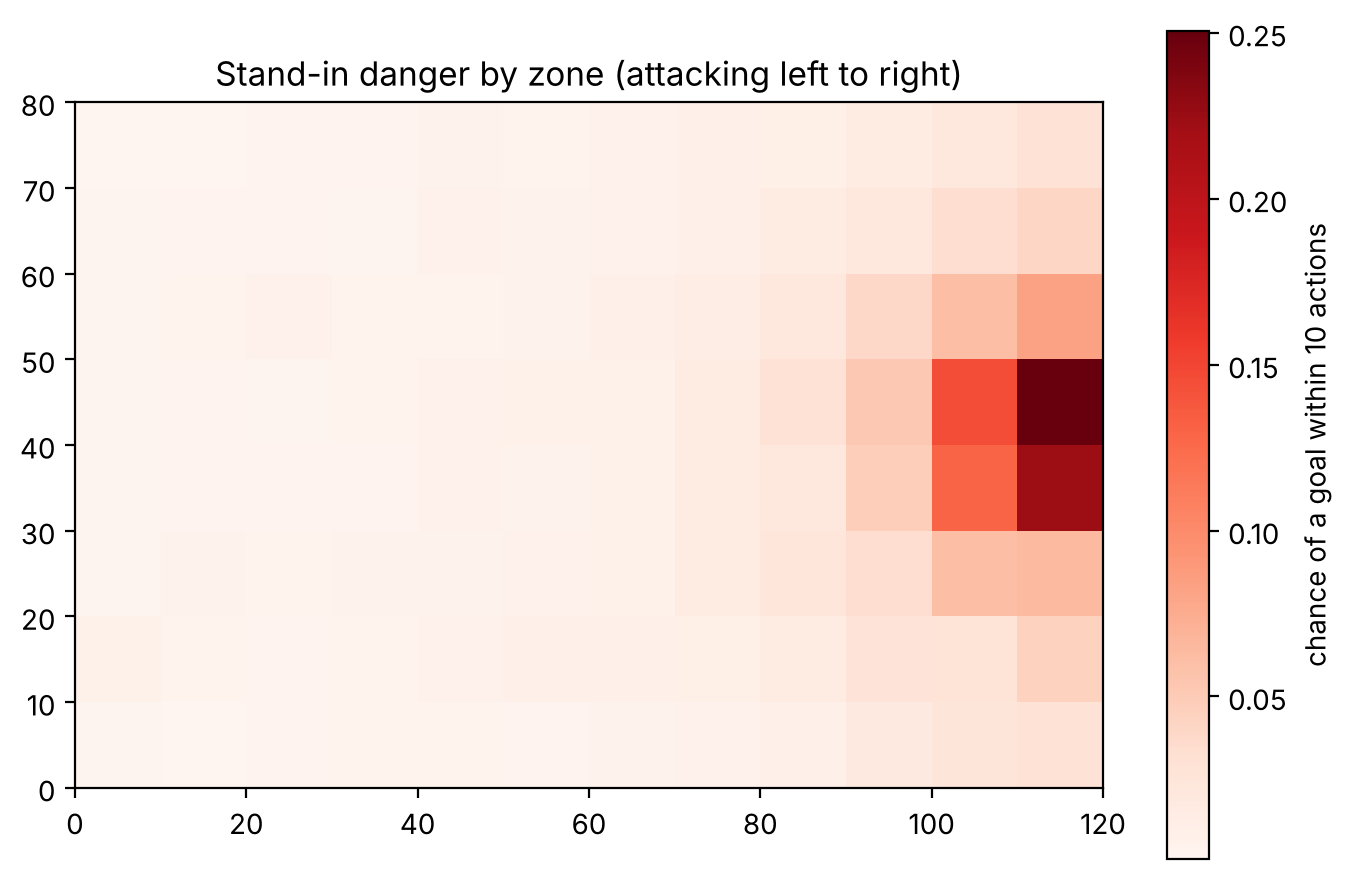

In [17]:
ZONE = 10
COLUMNS_X = 12
COLUMNS_Y = 8

split = pd.read_parquet("../outputs/xpass_oof.parquet", columns=["match_id", "test"]).drop_duplicates()
actions = actions.merge(split, on="match_id", how="left")


def zoneOf(x, y):
    """Zone number of a point on the pitch."""
    column = np.clip((x // ZONE).astype(int), 0, COLUMNS_X - 1)
    row = np.clip((y // ZONE).astype(int), 0, COLUMNS_Y - 1)
    return column * COLUMNS_Y + row


def zoneDanger(actions):
    """Chance of a goal within 10 actions for every zone, from training matches."""
    train = actions[actions["test"] == False]
    zones = zoneOf(train["x"].to_numpy(), train["y"].to_numpy())
    table = pd.Series(train["scores"].to_numpy()).groupby(zones).mean()
    return table.reindex(range(COLUMNS_X * COLUMNS_Y), fill_value=0)


danger = zoneDanger(actions)

grid = danger.to_numpy().reshape(COLUMNS_X, COLUMNS_Y).T
fig, ax = plt.subplots(figsize=(7, 4.5))
image = ax.imshow(grid, origin="lower", extent=[0, 120, 0, 80], cmap="Reds")
plt.colorbar(image, ax=ax, label="chance of a goal within 10 actions")
ax.set_title("Stand-in danger by zone (attacking left to right)")
plt.tight_layout()
plt.show()

In [18]:
def standInValues(actions, danger):
    """Danger after the action minus danger before it."""
    before = danger.to_numpy()[zoneOf(actions["x"].to_numpy(), actions["y"].to_numpy())]
    endX = actions["endX"].fillna(actions["x"]).to_numpy()
    endY = actions["endY"].fillna(actions["y"]).to_numpy()
    after = danger.to_numpy()[zoneOf(endX, endY)]
    after = np.where(actions["completed"].to_numpy() == 1, after, 0)
    values = after - before
    values = np.where(actions["type"].to_numpy() == "Shot", 0, values)
    return values


def addValues(actions, danger):
    """Use Anish's action values if they exist, otherwise the stand-in."""
    actions = actions.copy()
    actions["value"] = standInValues(actions, danger)
    actions["valueSource"] = "zone stand-in"
    if VALUES_FILE.exists():
        ours = pd.read_parquet(VALUES_FILE, columns=["id", VALUES_COLUMN]).rename(columns={VALUES_COLUMN: "modelValue"})
        actions = actions.merge(ours, on="id", how="left")
        found = actions["modelValue"].notna()
        actions.loc[found, "value"] = actions.loc[found, "modelValue"]
        actions.loc[found, "valueSource"] = "danger model"
    return actions


actions = addValues(actions, danger)

print(actions["valueSource"].value_counts())
print(actions.groupby("type")["value"].agg(["mean", "sum"]).round(4))

valueSource
zone stand-in    832998
Name: count, dtype: int64
           mean       sum
type                     
Carry    0.0015  547.1359
Dribble -0.0106 -140.5825
Pass    -0.0001  -52.8257
Shot     0.0000    0.0000


Shots get 0 here because their value is already counted in xG, and a failed pass or dribble gives the danger back, so it counts as a loss.

## Minutes played
From the lineups: starters begin at minute 0, substitutes at the minute they come on, and a player leaves at the minute he is replaced or at the end of the match. Names come from player_nickname in the lineups, because the events use full legal names.

In [19]:
def loadLineups(matchId):
    """Lineups of one match, saved after the first download."""
    folder = f"{RAW}/lineups"
    os.makedirs(folder, exist_ok=True)
    path = f"{folder}/{matchId}.pkl"
    if os.path.exists(path):
        return pd.read_pickle(path)
    lineups = sb.lineups(match_id=matchId)
    pd.to_pickle(lineups, path)
    return lineups


def timeToMinute(text):
    """Turn a "mm:ss" time into minutes."""
    minutes, seconds = text.split(":")
    return int(minutes) + int(seconds) / 60


def matchMinutes(matchId, events):
    """Minutes played by every player in one match."""
    end = events.loc[events["period"] <= 4, "minute"].max() + 1
    lineups = loadLineups(matchId)
    rows = []
    for team, players in lineups.items():
        for index, player in players.iterrows():
            spells = player["positions"]
            if len(spells) == 0:
                continue
            start = timeToMinute(spells[0]["from"])
            last = spells[-1]["to"]
            if last is None:
                finish = end
            else:
                finish = timeToMinute(last)
            if pd.notna(player["player_nickname"]):
                nickname = player["player_nickname"]
            else:
                nickname = player["player_name"]
            rows.append({"match_id": matchId, "team": team, "player_id": player["player_id"], "name": nickname, "minutes": max(finish - start, 0)})
    return pd.DataFrame(rows)

In [20]:
allMinutes = []
for matchId in matches360["match_id"]:
    allMinutes.append(matchMinutes(matchId, loadEvents(matchId)))

minutes = pd.concat(allMinutes, ignore_index=True)

print("Player-match rows:", len(minutes))
print(minutes["minutes"].describe().round(1))

Player-match rows: 13060
count    13060.0
mean        70.3
std         32.4
min          0.0
25%         42.3
50%         83.3
75%         96.0
max        127.0
Name: minutes, dtype: float64


In [21]:
print("Rows where the lineup times gave a negative length (set to 0):", (minutes["minutes"] == 0).sum())

Rows where the lineup times gave a negative length (set to 0): 1


## Danger created per 90
Only players with at least 270 minutes (three full matches), so one lucky match can't put a player at the top.

In [22]:
MIN_MINUTES = 270
TOP = 15


def playerTable(actions, minutes):
    """Danger added per 90 minutes for every player."""
    created = actions.groupby("player_id")["value"].sum()
    played = minutes.groupby("player_id")["minutes"].sum()
    names = minutes.groupby("player_id")["name"].first()
    teams = minutes.groupby("player_id")["team"].agg(lambda team: team.value_counts().index[0])
    table = pd.DataFrame({"name": names, "team": teams, "minutes": played, "danger": created})
    table = table.dropna(subset=["minutes"])
    table["danger"] = table["danger"].fillna(0)
    table = table[table["minutes"] >= MIN_MINUTES]
    table["dangerPer90"] = table["danger"] / table["minutes"] * 90
    return table.sort_values("dangerPer90", ascending=False)


players = playerTable(actions, minutes)

print("Players with", MIN_MINUTES, "+ minutes:", len(players))
print(players.head(TOP).round(3).to_string())

players.to_csv("../outputs/influential_players.csv")

Players with 270 + minutes: 1058
                          name                 team   minutes  danger  dangerPer90
player_id                                                                         
10595.0               Raphinha               Brazil   331.383   2.097        0.569
10155.0              Mapi León        Spain Women's   406.000   2.188        0.485
316046.0          Lamine Yamal                Spain   518.500   2.482        0.431
5574.0              Toni Kroos              Germany  1043.967   4.972        0.429
32838.0           Claudia Pina        Spain Women's   392.500   1.738        0.399
5177.0       Aleksandr Golovin               Russia   438.000   1.915        0.394
49835.0       Teresa Abelleira        Spain Women's   708.717   3.055        0.388
15471.0            Selma Bacha       France Women's   947.383   3.764        0.358
25770.0           Lisa Boattin        Italy Women's   869.650   3.394        0.351
8286.0     Leonardo Spinazzola                Italy   

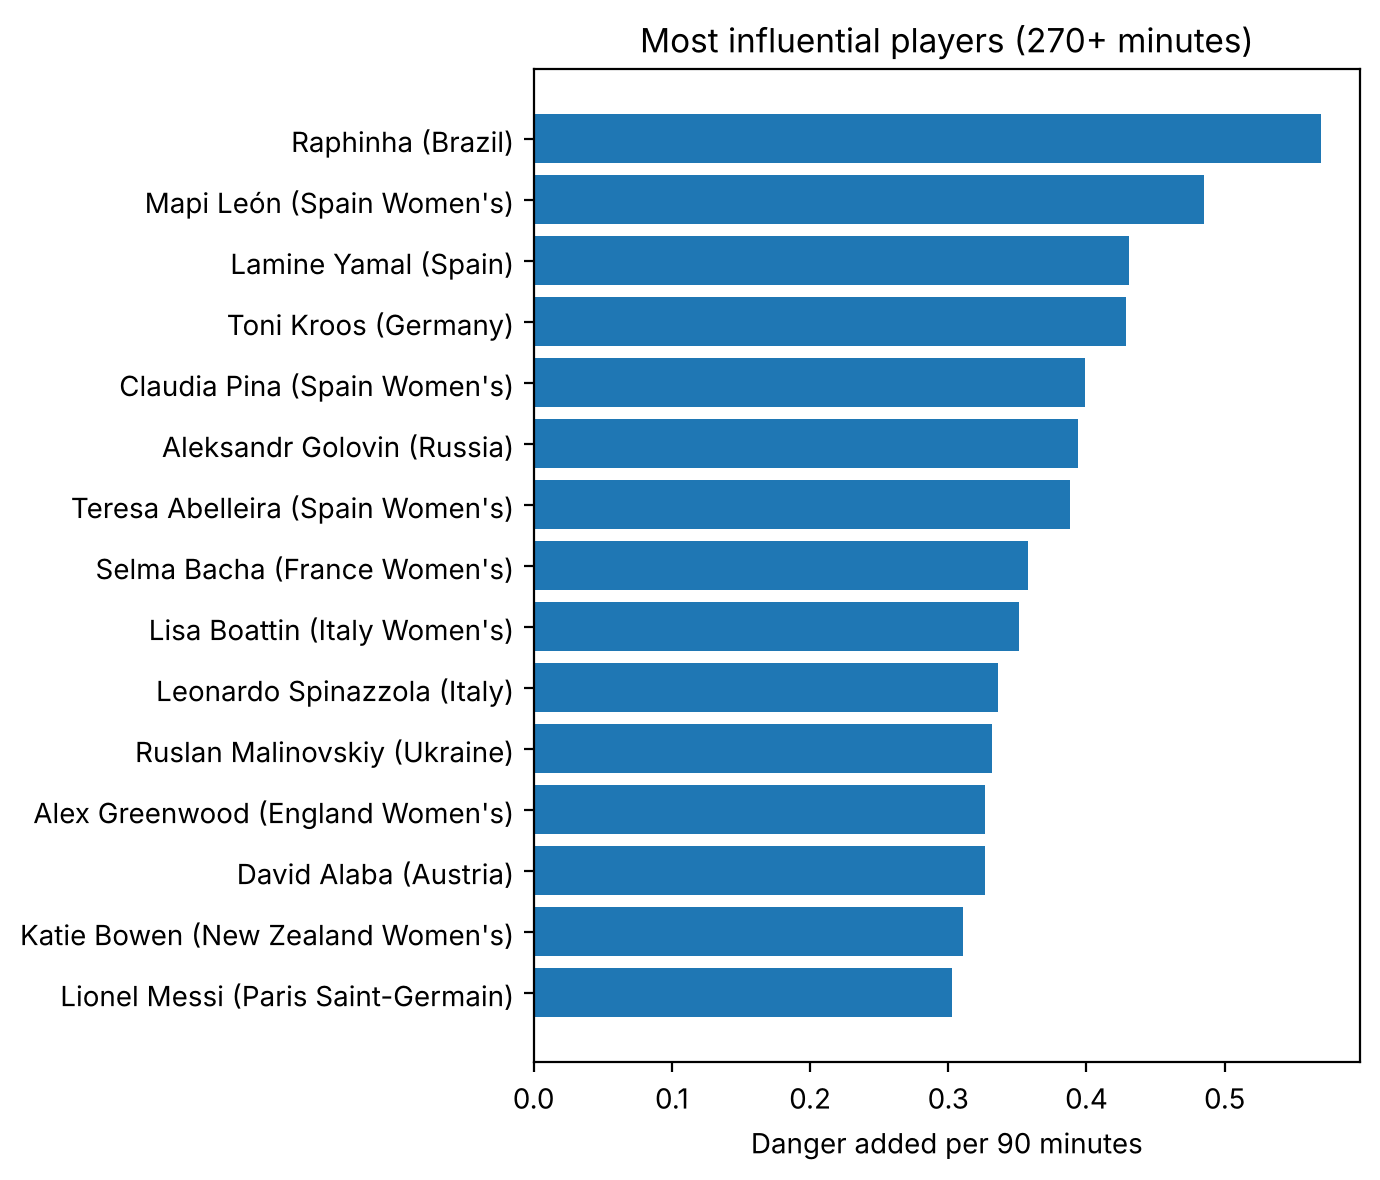

In [23]:
def plotPlayers(players, ax):
    """Bar chart of the most influential players."""
    top = players.head(TOP).iloc[::-1]
    labels = top["name"] + " (" + top["team"] + ")"
    ax.barh(labels, top["dangerPer90"])
    ax.set_xlabel("Danger added per 90 minutes")
    ax.set_title("Most influential players (" + str(MIN_MINUTES) + "+ minutes)")


fig, ax = plt.subplots(figsize=(7, 6))
plotPlayers(players, ax)
plt.tight_layout()
plt.savefig("../outputs/fig2_players.png", dpi=150)
plt.show()

## Fig. 2: all three panels together

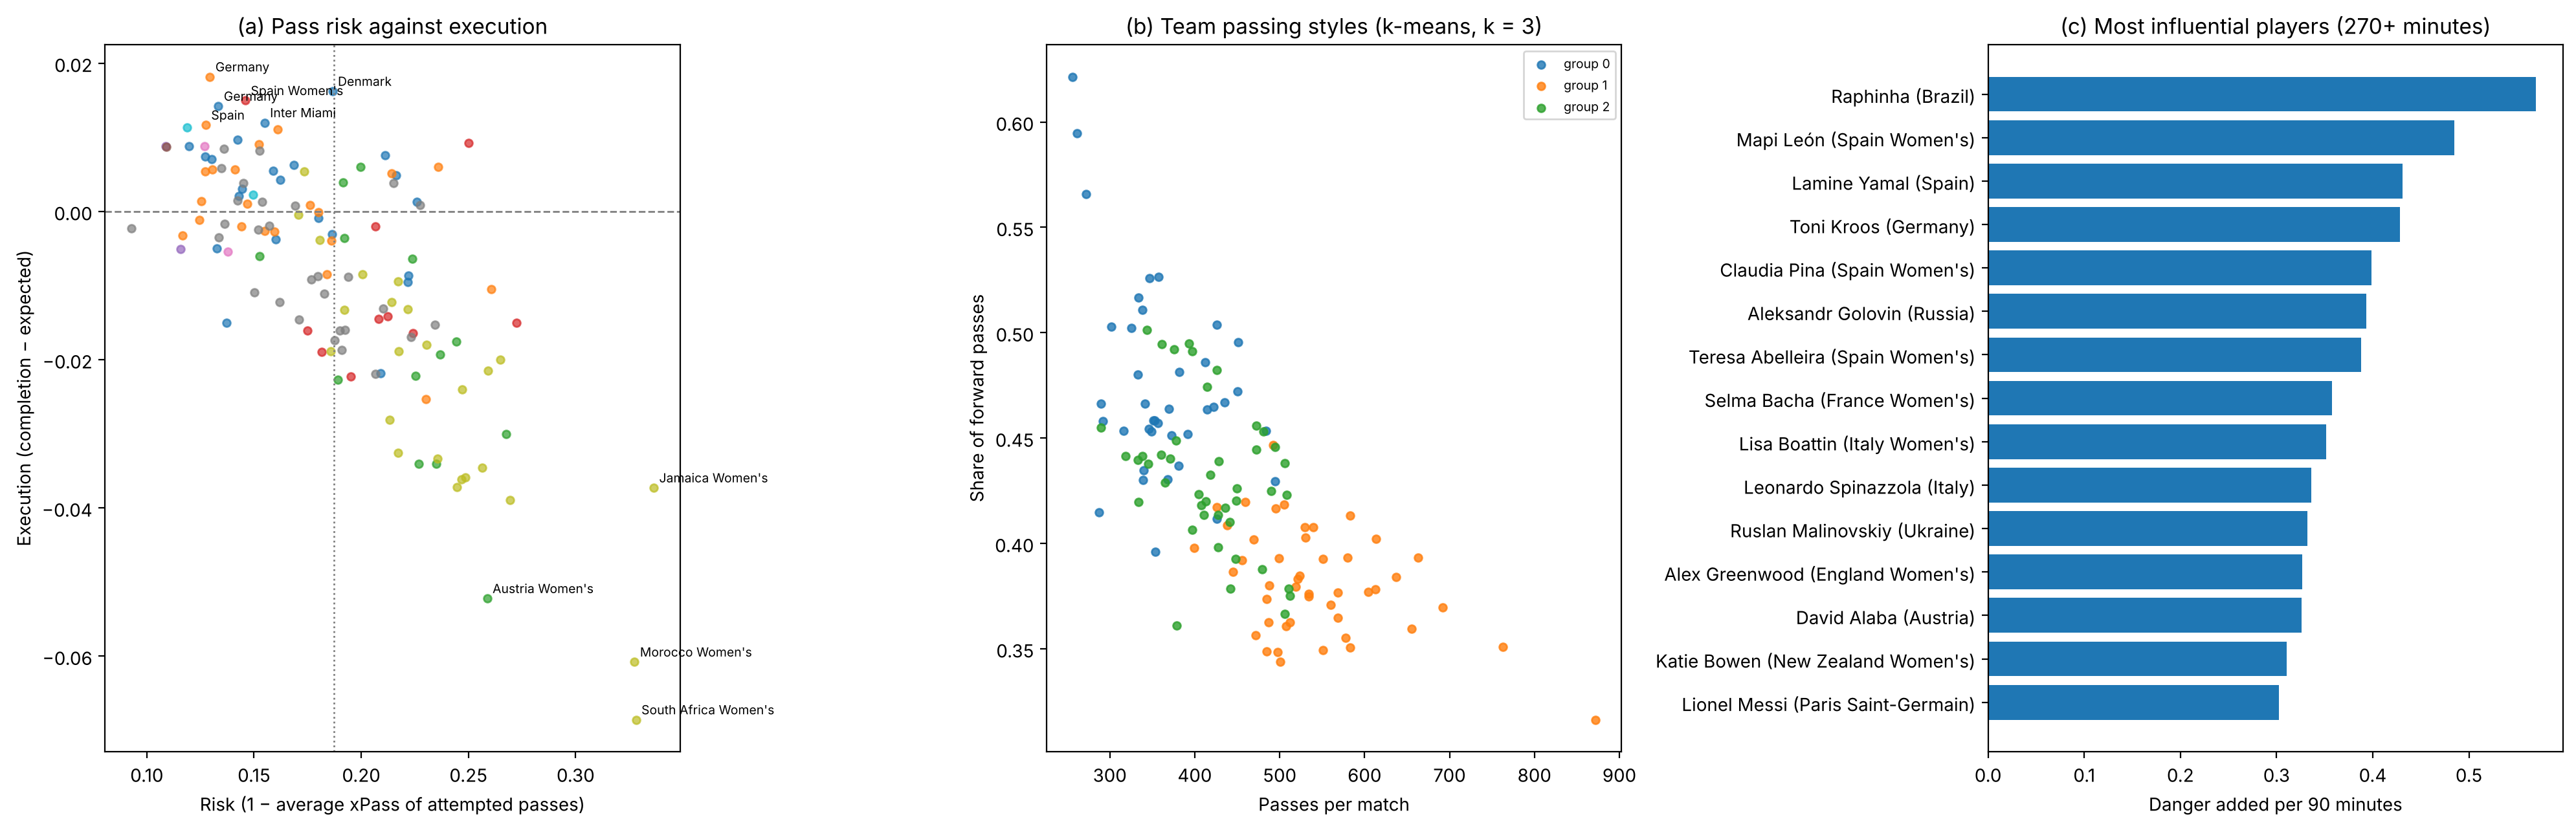

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
plotRisk(risk, axes[0])
plotStyles(styles, axes[1])
plotPlayers(players, axes[2])
for ax, letter in zip(axes, ["(a)", "(b)", "(c)"]):
    ax.set_title(letter + " " + ax.get_title())
plt.tight_layout()
plt.savefig("../outputs/fig2.png", dpi=200)
plt.show()